In [1]:
!mamba install pandas 

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.133 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [2]:
import pandas as pd

In [1]:
!mamba install pandas 
import pandas as pd
import matplotlib.pyplot as plt

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.966 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [13]:
df = pd.read_csv('childhood maltreatment Study Data.csv')

# Remove accidental spaces in column names
df.columns = df.columns.str.strip()
print(df.head())
print(df.info())
print(df.describe(include="all"))

      author  year              cohort   country  percent_female  \
0    Simpson  2019       Bendall_EPPIC  Austalia            40.7   
1    Simpson  2019       Bendall_EPPIC  Austalia            40.7   
2  Bernstein  1994  Ruggiero_Addiction       USA            14.7   
3  Bernstein  1994  Ruggiero_Addiction       USA            14.7   
4  Bernstein  1994  Ruggiero_Addiction       USA            14.7   

                                           ethnicity  sample  \
0                                                NaN       2   
1                                                NaN       2   
2  African American, 51.2%; Latino, 30.9%; white ...       2   
3  African American, 51.2%; Latino, 30.9%; white ...       2   
4  African American, 51.2%; Latino, 30.9%; white ...       2   

       sample_diagnosis_data  sample_mh sample_subgroup  ...  \
0    first episode psychosis  psychosis       psychotic  ...   
1    first episode psychosis  psychosis        controls  ...   
2  Drug or Alc

In [11]:
data_dictionary = pd.read_csv('data_extraction_table.csv')
data_dictionary

,Variable,Description
0,author,First author of the study
1,year,Year the study was published
2,cohort,Name of the cohort or study sample
3,country,Country where the study was conducted
4,percent_female,Percentage of female participants in the sample
5,ethnicity,Description of ethnicity of the sample
6,sample,Sample type: 0 = population representative; 1 ...
7,sample_diagnosis_data,If clinical sample: sample diagnosis (as descr...
8,sample_mh,If clinical sample: coding of sample mental he...
9,sample_subgroup,If stability was tested within a particular su...


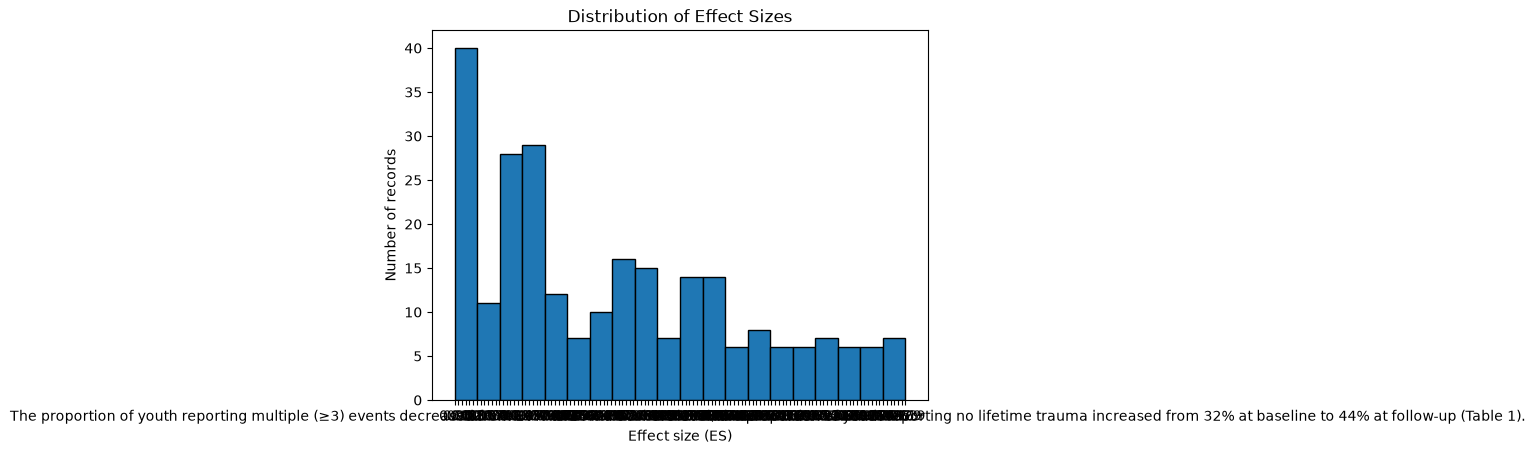

In [16]:
import matplotlib.pyplot as plt

plt.hist(df["ES"].dropna(), bins=20, edgecolor="black")
plt.xlabel("Effect size (ES)")
plt.ylabel("Number of records")
plt.title("Distribution of Effect Sizes")
plt.show()

In [17]:
df.columns = df.columns.str.strip()

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the file
df = pd.read_csv('childhood maltreatment Study Data.csv')

# Clean column names and convert effect size to numbers
df.columns = df.columns.str.strip()
df["ES"] = pd.to_numeric(df["ES"], errors="coerce")

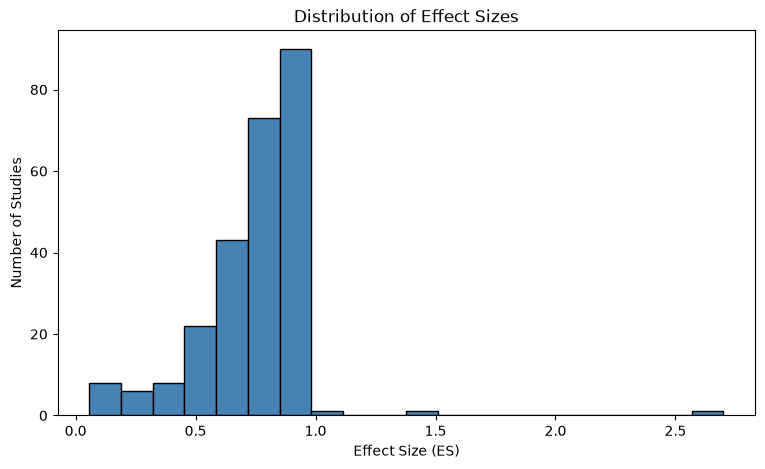

In [24]:
plt.figure(figsize=(9, 5))

plt.hist(df["ES"].dropna(), bins=20, edgecolor="black", color="steelblue")

plt.title("Distribution of Effect Sizes")
plt.xlabel("Effect Size (ES)")
plt.ylabel("Number of Studies")
plt.show()

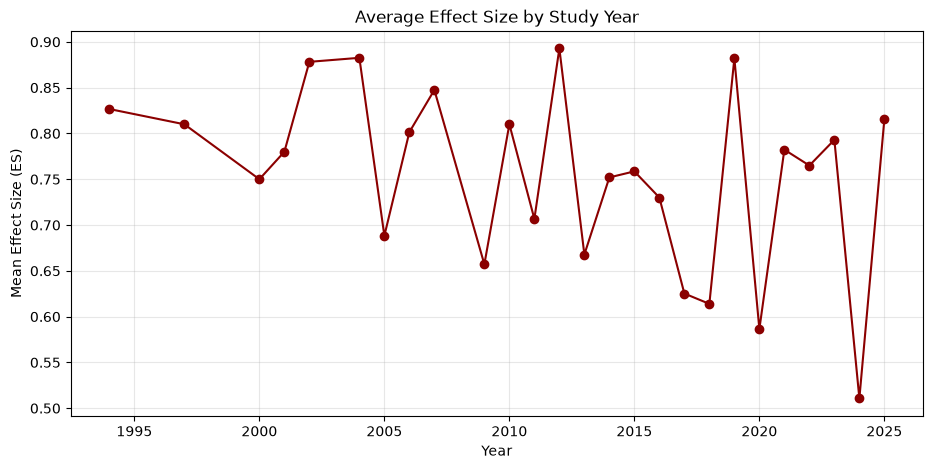

In [25]:
year_summary = (
    df.dropna(subset=["ES"])
      .groupby("year", as_index=False)["ES"]
      .mean()
      .sort_values("year")
)

plt.figure(figsize=(11, 5))

plt.plot(
    year_summary["year"],
    year_summary["ES"],
    marker="o",
    color="darkred"
)

plt.title("Average Effect Size by Study Year")
plt.xlabel("Year")
plt.ylabel("Mean Effect Size (ES)")
plt.grid(True, alpha=0.3)
plt.show()

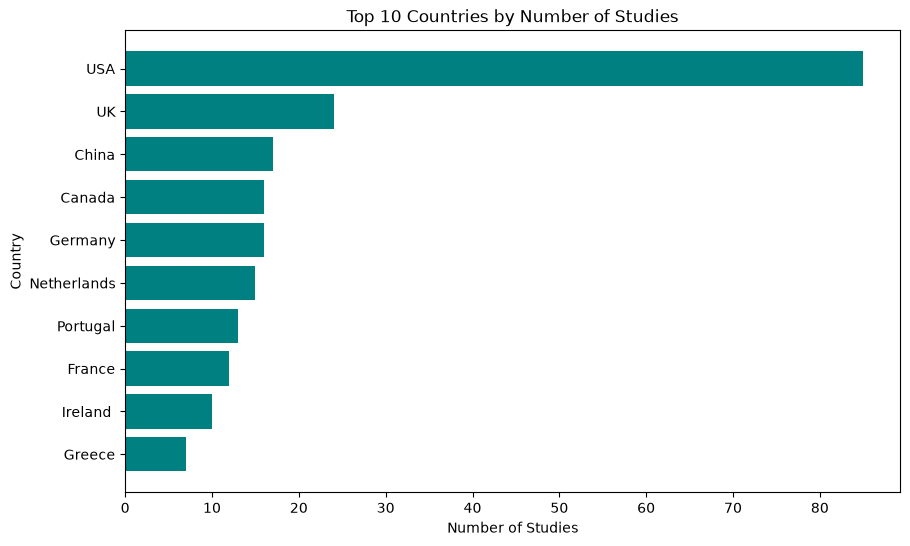

In [26]:
country_counts = df["country"].value_counts().head(10)

plt.figure(figsize=(10, 6))

plt.barh(country_counts.index, country_counts.values, color="teal")
plt.title("Top 10 Countries by Number of Studies")
plt.xlabel("Number of Studies")
plt.ylabel("Country")
plt.gca().invert_yaxis()  # puts the largest country at the top
plt.show()

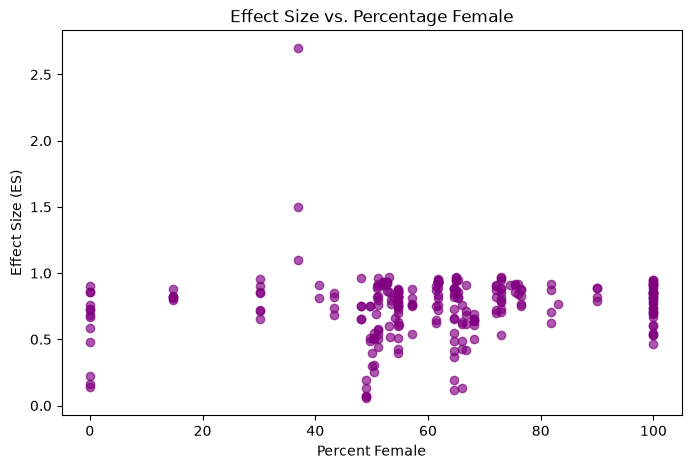

In [27]:
plot_df = df.dropna(subset=["percent_female", "ES"])

plt.figure(figsize=(8, 5))

plt.scatter(
    plot_df["percent_female"],
    plot_df["ES"],
    alpha=0.65,
    color="purple"
)

plt.title("Effect Size vs. Percentage Female")
plt.xlabel("Percent Female")
plt.ylabel("Effect Size (ES)")
plt.show()